# Failure-Rate Extensions of Algorithm 1: Worked Examples

This notebook mirrors `extensions.py` cell for cell. It gives one worked example for each failure-rate extension of Algorithm 1 in Section 5 of *Estimating Distributions with Failure Rate Properties from Noisy Quantile Data* by Chan, Chen, Fernandes, and Maaz (2026): decreasing failure rate (DFR), increasing failure rate average (IFRA), increasing generalized failure rate (IGFR), and new better than used (NBU).

Each example simulates noisy quantile data from a known ground truth in the relevant shape class, fits the corresponding estimator from `fitting.py`, prints the simulated counts, and plots $\hat F$ against $F_0$. The four examples share one observation design, and a final cell assembles their panels into the combined figure used in the manuscript appendix. Run the cells in order: the combined figure uses the panels collected by the four example cells.

## Setup

Imports, figure settings, and the shared observation design.

- All four examples use the knots $\{1, 2, 4, 8\}$ with $n_i = 250$ trials each on the support $[0, \infty)$, and are plotted on $[0, 12]$. The knot set was chosen by a search over four-knot subsets of $\{1, \ldots, 10\}$ (see `AI/ai-logs/2026-11-17.md`).
- `eval_cdf` evaluates the symbolic `Piecewise` cdf an estimator returns on a grid, clipped to $[0, 1]$, suppressing the harmless overflow warnings that non-selected tail branches raise.
- `panels` collects each example's curves for the combined figure.
- Figures use LaTeX text rendering (`text.usetex = True`), so a working LaTeX installation is required.

In [7]:
"""
extensions.py

Worked examples for the failure-rate extensions of Algorithm 1 (manuscript
Section 5). Each example simulates noisy quantile data from a known parametric
ground-truth cdf in the relevant shape class, fits the corresponding estimator
from ``fitting.py``, and plots the fit against the ground truth.

Currently implemented:
    - Decreasing Failure Rate (DFR): ``fit_cdf_dfr``
    - Increasing Failure Rate Average (IFRA): ``fit_cdf_ifra``
    - Increasing Generalized Failure Rate (IGFR): ``fit_cdf_igfr``
    - New Better Than Used (NBU): ``fit_cdf_nbu``
"""

import os

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.stats import weibull_min, lomax

from fitting import fit_cdf_dfr, fit_cdf_ifra, fit_cdf_igfr, fit_cdf_nbu

plt.rcParams.update({
    'axes.labelsize':  22,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}",
})

os.makedirs('results/plots', exist_ok=True)

# Package-wide symbolic variable used by the sympy cdfs the fit functions return.
x_sym = sp.symbols('x')

# Common observation design shared by all four examples: four integer knots and
# n_i trials at each knot. The knot set was chosen by a search over all four-knot
# subsets of {1, ..., 10} (5 simulated datasets each, sup-norm error of the fitted
# cdf on [0, 12] averaged over datasets and over the four ground truths); the top
# sets are within Monte Carlo noise of each other, and {1, 2, 4, 8} is among them
# while spanning the plotting range and being geometrically spaced. See
# AI/ai-logs/2026-11-17.md. All panels are plotted on the same x-range.
x_knots_common = np.array([1.0, 2.0, 4.0, 8.0])
n_i_common = 250
x_max_common = 12.0

# Each example appends its curves here so that a combined 2x2 figure (manuscript
# Appendix, "Visualization") can be drawn at the end of the script.
panels = []


def eval_cdf(expr, x_vals):
    """Evaluate a symbolic cdf on a grid, clipped to [0, 1].

    The extension estimators return a sympy ``Piecewise`` in ``x_sym``; lambdify
    with numpy and suppress the harmless overflow/invalid/divide warnings the
    exponential, power-law, or log tails can raise when non-selected branches are
    evaluated outside their interval (e.g. ``log(0)`` past a finite support).
    """
    fn = sp.lambdify(x_sym, expr, 'numpy')
    with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
        vals = np.asarray(fn(x_vals), dtype=float)
    return np.clip(vals, 0.0, 1.0)

## Decreasing Failure Rate (DFR)

Ground truth: Weibull with shape $0.5$ and scale $3$. A Weibull with shape $k < 1$ has a strictly decreasing hazard, and $t(x) = \log(1 - F(x)) = -(x/\lambda)^k$ is convex, which is exactly the class `fit_cdf_dfr` estimates: a convex program in $t$-space with the concavity constraints reversed, piecewise-linear interpolation, and a linear tail to infinity. Saved to `results/plots/extension_dfr_example.png`.

DFR example (Weibull shape=0.50, scale=3.00)
  x= 1.0:  y/n = 114/250 = 0.456   (F_0 = 0.439)
  x= 2.0:  y/n = 138/250 = 0.552   (F_0 = 0.558)
  x= 4.0:  y/n = 171/250 = 0.684   (F_0 = 0.685)
  x= 8.0:  y/n = 200/250 = 0.800   (F_0 = 0.805)


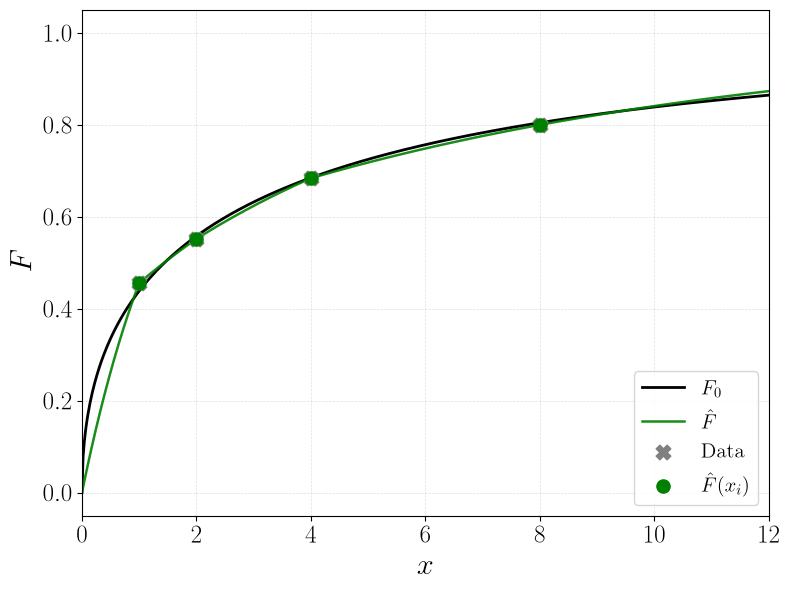

In [8]:
# ============================================================================
# Decreasing Failure Rate (DFR)
# ============================================================================
#
# Ground truth: a Weibull with shape k < 1 is DFR. Its hazard
# h(x) = (k/lambda)(x/lambda)^{k-1} is strictly decreasing for k < 1, and the
# log-survival t(x) = log(1 - F(x)) = -(x/lambda)^k is convex -- exactly the
# shape class fit_cdf_dfr estimates. Support is [0, inf), so l = 0.

l = 0.0
shape, scale = 0.5, 3.0                      # k = 0.5 < 1  => DFR
ground_truth = weibull_min(shape, scale=scale)
F0 = ground_truth.cdf

# Noisy-quantile observation design: k knots strictly inside (0, inf), each with
# n_i Bernoulli trials recording whether a draw falls below the knot.
x_knots = x_knots_common.copy()
n_i = n_i_common
n_trials = n_i * np.ones(len(x_knots), dtype=int)

# Simulate y_i ~ Binomial(n_i, F_0(x_i)).
np.random.seed(0)
true_p = F0(x_knots)
y_samples = np.random.binomial(n_trials, true_p)

print("DFR example (Weibull shape=%.2f, scale=%.2f)" % (shape, scale))
for xi, yi, ni, pi in zip(x_knots, y_samples, n_trials, true_p):
    print(f"  x={xi:>4.1f}:  y/n = {yi:>3d}/{ni:<3d} = {yi / ni:.3f}   (F_0 = {pi:.3f})")

# Fit the DFR estimator (convex program in t-space + PWL interpolation + linear
# tail to infinity). Returns a proper DFR cdf on [0, inf).
fitted = fit_cdf_dfr(x_knots, n_trials, y_samples, l=l)

# Evaluation grid. The support is unbounded; all examples share one plotting range.
x_max = x_max_common
x_grid = np.linspace(l, x_max, 600)
y_true = F0(x_grid)
y_fit = eval_cdf(fitted, x_grid)
fhat_knots = eval_cdf(fitted, x_knots)
panels.append(dict(title='DFR', x_grid=x_grid, y_true=y_true, y_fit=y_fit,
                   x_knots=x_knots, data=y_samples / n_trials, fhat=fhat_knots,
                   xlim=(l, x_max)))

# ---- Figure: cdf fit in F-space ----
fig, ax_cdf = plt.subplots(figsize=(8, 6))

ax_cdf.plot(x_grid, y_true, color='black', lw=2, label=r'$F_0$')
ax_cdf.plot(x_grid, y_fit, color='green', lw=1.8, alpha=0.9, label=r'$\hat{F}$')
ax_cdf.scatter(x_knots, y_samples / n_trials, color='grey', marker='X',
               s=110, zorder=5, label='Data')
ax_cdf.scatter(x_knots, fhat_knots, color='green', marker='o',
               s=90, zorder=6, label=r'$\hat{F}(x_i)$')
ax_cdf.set_xlabel(r'$x$')
ax_cdf.set_ylabel(r'$F$')
ax_cdf.set_xlim(l, x_max)
ax_cdf.set_ylim(-0.05, 1.05)
ax_cdf.grid(True, linestyle='--', alpha=0.4)
ax_cdf.legend(loc='lower right', fontsize=15)

plt.tight_layout()
plt.savefig('results/plots/extension_dfr_example.png', dpi=150, bbox_inches='tight')
plt.show()

## Increasing Failure Rate Average (IFRA)

Ground truth: a piecewise-exponential law with hazard $0.3$ on $[0, 1]$, $0.9$ on $[1, 2]$, and $0.7$ on $[2, \infty)$. The hazard drops at $x = 2$, so the law is not IFR, but the average hazard $H(x)/x = -t(x)/x$ is non-decreasing, so it is IFRA. `fit_cdf_ifra` imposes $-t(x_i)/x_i$ non-decreasing across the knots, interpolates linearly, and appends a linear tail. The printed table shows the average hazard rising while the hazard itself does not. Saved to `results/plots/extension_ifra_example.png`.


IFRA example (piecewise-constant hazard 0.3/0.9/0.7 on [0,1]/[1,2]/[2,inf))
  hazard         h = 0.3, 0.9, 0.7   (drops at x=2  => NOT IFR)
  average hazard H(x)/x  (non-decreasing  => IFRA):
      x= 1.0:  H(x)/x = 0.300
      x= 2.0:  H(x)/x = 0.600
      x= 3.0:  H(x)/x = 0.633
      x=10.0:  H(x)/x = 0.680
  x= 1.0:  y/n =  61/250 = 0.244   (F_0 = 0.259)
  x= 2.0:  y/n = 173/250 = 0.692   (F_0 = 0.699)
  x= 4.0:  y/n = 232/250 = 0.928   (F_0 = 0.926)
  x= 8.0:  y/n = 248/250 = 0.992   (F_0 = 0.995)


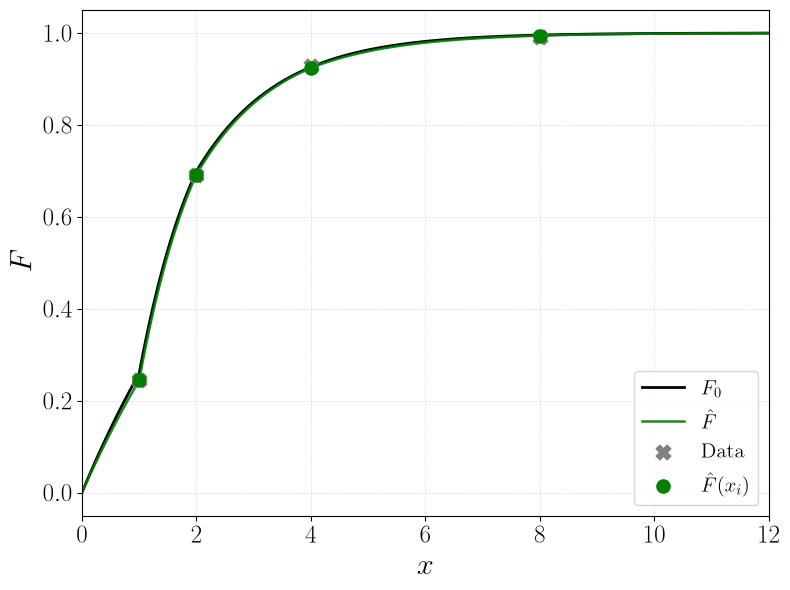

In [9]:
# ============================================================================
# Increasing Failure Rate Average (IFRA)
# ============================================================================
#
# Ground truth: a piecewise-exponential (piecewise-constant hazard) law that is
# IFRA but NOT IFR. The hazard is
#     h(x) = 0.3 on [0, 1],   0.9 on [1, 2],   0.7 on [2, inf).
# It drops from 0.9 to 0.7 at x = 2, so the hazard is non-monotone => not IFR.
# The average failure rate H(x)/x = -t(x)/x is nevertheless non-decreasing
# (0.30 at x=1, 0.60 at x=2, rising to 0.70 as x -> inf) => IFRA. Support [0, inf).

l = 0.0
hazard_rates = np.array([0.3, 0.9, 0.7])          # on [0,1], [1,2], [2, inf)
hazard_bps = np.array([1.0, 2.0])


def F0_ifra(x):
    """IFRA-but-not-IFR cdf: F = 1 - exp(-H) with a piecewise-constant hazard."""
    x = np.asarray(x, dtype=float)
    H = (hazard_rates[0] * np.clip(x, 0.0, hazard_bps[0])
         + hazard_rates[1] * np.clip(x - hazard_bps[0], 0.0, hazard_bps[1] - hazard_bps[0])
         + hazard_rates[2] * np.clip(x - hazard_bps[1], 0.0, None))
    return np.where(x < 0.0, 0.0, 1.0 - np.exp(-H))


F0 = F0_ifra

# Noisy-quantile observation design on [0, inf), shared with the other examples.
x_knots = x_knots_common.copy()
n_i = n_i_common
n_trials = n_i * np.ones(len(x_knots), dtype=int)

np.random.seed(0)
true_p = F0(x_knots)
y_samples = np.random.binomial(n_trials, true_p)

print("\nIFRA example (piecewise-constant hazard 0.3/0.9/0.7 on [0,1]/[1,2]/[2,inf))")
print("  hazard         h = 0.3, 0.9, 0.7   (drops at x=2  => NOT IFR)")
print("  average hazard H(x)/x  (non-decreasing  => IFRA):")
for xx in [1.0, 2.0, 3.0, 10.0]:
    avg_haz = -np.log(1.0 - F0(np.array([xx]))[0]) / xx
    print(f"      x={xx:>4.1f}:  H(x)/x = {avg_haz:.3f}")
for xi, yi, ni, pi in zip(x_knots, y_samples, n_trials, true_p):
    print(f"  x={xi:>4.1f}:  y/n = {yi:>3d}/{ni:<3d} = {yi / ni:.3f}   (F_0 = {pi:.3f})")

# Fit the IFRA estimator (convex program with -t/x non-decreasing + PWL
# interpolation + linear tail to infinity). Returns a proper IFRA cdf on [0, inf).
fitted = fit_cdf_ifra(x_knots, n_trials, y_samples, l=l)

x_max = x_max_common
x_grid = np.linspace(l, x_max, 600)
y_true = F0(x_grid)
y_fit = eval_cdf(fitted, x_grid)
fhat_knots = eval_cdf(fitted, x_knots)
panels.append(dict(title='IFRA', x_grid=x_grid, y_true=y_true, y_fit=y_fit,
                   x_knots=x_knots, data=y_samples / n_trials, fhat=fhat_knots,
                   xlim=(l, x_max)))

# ---- Figure: cdf fit in F-space ----
fig, ax_cdf = plt.subplots(figsize=(8, 6))

ax_cdf.plot(x_grid, y_true, color='black', lw=2, label=r'$F_0$')
ax_cdf.plot(x_grid, y_fit, color='green', lw=1.8, alpha=0.9, label=r'$\hat{F}$')
ax_cdf.scatter(x_knots, y_samples / n_trials, color='grey', marker='X',
               s=110, zorder=5, label='Data')
ax_cdf.scatter(x_knots, fhat_knots, color='green', marker='o',
               s=90, zorder=6, label=r'$\hat{F}(x_i)$')
ax_cdf.set_xlabel(r'$x$')
ax_cdf.set_ylabel(r'$F$')
ax_cdf.set_xlim(l, x_max)
ax_cdf.set_ylim(-0.05, 1.05)
ax_cdf.grid(True, linestyle='--', alpha=0.4)
ax_cdf.legend(loc='lower right', fontsize=15)

plt.tight_layout()
plt.savefig('results/plots/extension_ifra_example.png', dpi=150, bbox_inches='tight')
plt.show()

## Increasing Generalized Failure Rate (IGFR)

Ground truth: Lomax (Pareto Type II) with $\alpha = 2$ and scale $3$, $F(x) = 1 - (1 + x/3)^{-2}$. Its generalized failure rate $g(x) = x\,h(x) = \alpha x/(\text{scale} + x)$ is increasing while the hazard itself is decreasing, so this is the standard IGFR example from the pricing literature and is not IFR. `fit_cdf_igfr` imposes concavity of $t$ in $v = \log x$ (IGFR is IFR in log-$x$ space), with a power-law lower tail and a log-linear upper tail. Saved to `results/plots/extension_igfr_example.png`.


IGFR example (Lomax alpha=2.0, scale=3.0)
  hazard         h(x) = alpha/(scale+x)      (decreasing  => NOT IFR)
  gen. fail rate g(x) = x*h(x) = a*x/(s+x)   (increasing  => IGFR):
      x= 1.0:  g(x) = 0.500
      x= 2.0:  g(x) = 0.800
      x= 4.0:  g(x) = 1.143
      x= 8.0:  g(x) = 1.455
  x= 1.0:  y/n = 113/250 = 0.452   (F_0 = 0.438)
  x= 2.0:  y/n = 168/250 = 0.672   (F_0 = 0.640)
  x= 4.0:  y/n = 201/250 = 0.804   (F_0 = 0.816)
  x= 8.0:  y/n = 232/250 = 0.928   (F_0 = 0.926)


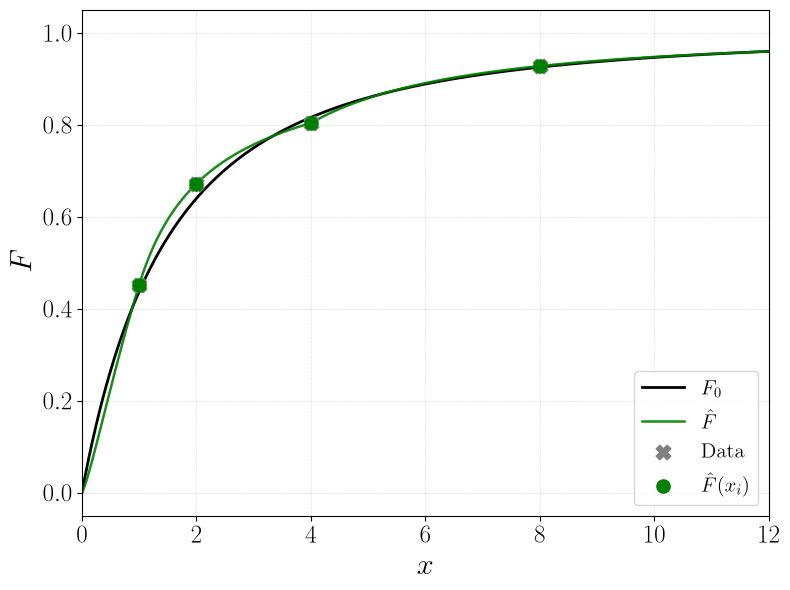

In [10]:
# ============================================================================
# Increasing Generalized Failure Rate (IGFR)
# ============================================================================
#
# Ground truth: a Lomax (Pareto Type II) law on [0, inf),
#     F(x) = 1 - (1 + x/scale)^(-alpha).
# Its generalized failure rate g(x) = x*h(x) = alpha*x/(scale + x) is increasing
# (IGFR), while the hazard h(x) = alpha/(scale + x) is DEcreasing -- so it is a
# canonical IGFR distribution that is not IFR (in fact DFR). This is the standard
# IGFR example from the pricing literature.

l = 0.0
alpha, scale = 2.0, 3.0
ground_truth = lomax(alpha, scale=scale)
F0 = ground_truth.cdf

# Noisy-quantile observation design on [0, inf), shared with the other examples.
x_knots = x_knots_common.copy()
n_i = n_i_common
n_trials = n_i * np.ones(len(x_knots), dtype=int)

np.random.seed(0)
true_p = F0(x_knots)
y_samples = np.random.binomial(n_trials, true_p)

print("\nIGFR example (Lomax alpha=%.1f, scale=%.1f)" % (alpha, scale))
print("  hazard         h(x) = alpha/(scale+x)      (decreasing  => NOT IFR)")
print("  gen. fail rate g(x) = x*h(x) = a*x/(s+x)   (increasing  => IGFR):")
for xx in [1.0, 2.0, 4.0, 8.0]:
    g_val = alpha * xx / (scale + xx)
    print(f"      x={xx:>4.1f}:  g(x) = {g_val:.3f}")
for xi, yi, ni, pi in zip(x_knots, y_samples, n_trials, true_p):
    print(f"  x={xi:>4.1f}:  y/n = {yi:>3d}/{ni:<3d} = {yi / ni:.3f}   (F_0 = {pi:.3f})")

# Fit the IGFR estimator (IFR in v = log x: concavity in log-x + power-law lower
# tail + log-linear upper tail). Returns a proper IGFR cdf on [0, inf).
fitted = fit_cdf_igfr(x_knots, n_trials, y_samples, l=l)

x_max = x_max_common
x_grid = np.linspace(l, x_max, 600)
y_true = F0(x_grid)
y_fit = eval_cdf(fitted, x_grid)
fhat_knots = eval_cdf(fitted, x_knots)
panels.append(dict(title='IGFR', x_grid=x_grid, y_true=y_true, y_fit=y_fit,
                   x_knots=x_knots, data=y_samples / n_trials, fhat=fhat_knots,
                   xlim=(l, x_max)))

# ---- Figure: cdf fit in F-space ----
fig, ax_cdf = plt.subplots(figsize=(8, 6))

ax_cdf.plot(x_grid, y_true, color='black', lw=2, label=r'$F_0$')
ax_cdf.plot(x_grid, y_fit, color='green', lw=1.8, alpha=0.9, label=r'$\hat{F}$')
ax_cdf.scatter(x_knots, y_samples / n_trials, color='grey', marker='X',
               s=110, zorder=5, label='Data')
ax_cdf.scatter(x_knots, fhat_knots, color='green', marker='o',
               s=90, zorder=6, label=r'$\hat{F}(x_i)$')
ax_cdf.set_xlabel(r'$x$')
ax_cdf.set_ylabel(r'$F$')
ax_cdf.set_xlim(l, x_max)
ax_cdf.set_ylim(-0.05, 1.05)
ax_cdf.grid(True, linestyle='--', alpha=0.4)
ax_cdf.legend(loc='lower right', fontsize=15)

plt.tight_layout()
plt.savefig('results/plots/extension_igfr_example.png', dpi=150, bbox_inches='tight')
plt.show()

## New Better Than Used (NBU)

Ground truth: a constructed law with a piecewise-linear cumulative hazard $H$ that is superadditive, so $t = -H$ is subadditive and the law is NBU, but whose average hazard $H(x)/x$ is non-monotone, so it is not IFRA. `fit_cdf_nbu` solves the lattice subadditivity program on the grid spanned by the knots (spacing inferred as their greatest common divisor), interpolates linearly, and appends a linear tail. The lattice spacing does not change the attained likelihood, only the shape between knots. Saved to `results/plots/extension_nbu_example.png`.


NBU example (constructed: H superadditive, H(x)/x non-monotone)
  cumulative hazard H is superadditive       => NBU
  average hazard H(x)/x  (NON-monotone  => NOT IFRA):
      x= 1.0:  H(x)/x = 0.300
      x= 2.0:  H(x)/x = 0.375
      x= 3.0:  H(x)/x = 0.350
      x= 4.0:  H(x)/x = 0.375
      x= 5.0:  H(x)/x = 0.360
      x= 6.0:  H(x)/x = 0.375
  x= 1.0:  y/n =  61/250 = 0.244   (F_0 = 0.259)
  x= 2.0:  y/n = 131/250 = 0.524   (F_0 = 0.528)
  x= 4.0:  y/n = 193/250 = 0.772   (F_0 = 0.777)
  x= 8.0:  y/n = 231/250 = 0.924   (F_0 = 0.950)


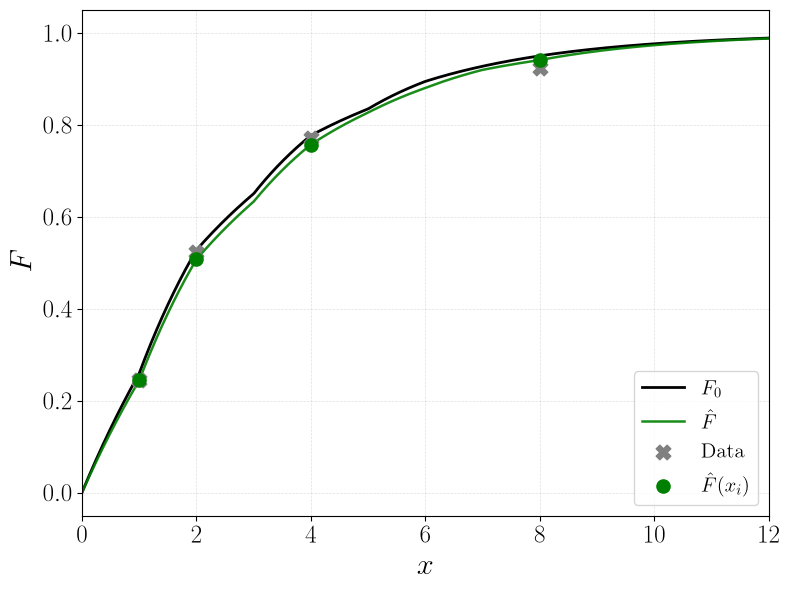

In [11]:
# ============================================================================
# New Better Than Used (NBU)
# ============================================================================
#
# Ground truth: a hand-built law on [0, inf) that is NBU but NOT IFRA (and not
# IFR). NBU <=> t = log(1-F) subadditive <=> cumulative hazard H = -t
# superadditive. IFRA <=> H(x)/x non-decreasing (star-shaped). We use a
# piecewise-linear H that is superadditive (verified) but whose average hazard
# H(x)/x dips, so it is NBU yet not IFRA. H is scaled by a constant (which
# preserves both properties) to spread the cdf over the plotting range.

l = 0.0
_nbu_scale = 0.3
nbu_x = np.array([0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0])
nbu_H = _nbu_scale * np.array([0.0, 1.0, 2.5, 3.5, 5.0, 6.0, 7.5])  # superadditive
nbu_tail_slope = _nbu_scale * 1.25                                  # H(x)=slope*x for x>6


def F0_nbu(x):
    """NBU-but-not-IFRA cdf: F = 1 - exp(-H), H superadditive, H(x)/x non-monotone."""
    x = np.asarray(x, dtype=float)
    below = np.interp(x, nbu_x, nbu_H)        # PWL on [0, 6]
    tail = nbu_tail_slope * x                 # 1.25*scale * x for x > 6 (continuous at 6)
    H = np.where(x <= 6.0, below, tail)
    return np.where(x < 0.0, 0.0, 1.0 - np.exp(-H))


F0 = F0_nbu

# Noisy-quantile observation design, shared with the other examples. The integer
# knots share a lattice whose spacing fit_cdf_nbu infers as their gcd. The lattice
# choice does not affect the attained likelihood: the grid problem is a tight
# relaxation of the continuous NBU problem for any lattice containing the knots
# (every continuous NBU t restricts to feasible grid values, and the PWL
# reconstruction extends any optimal grid values), so the coarsest lattice is
# simply the cheapest. A finer delta only changes the shape between knots.
x_knots = x_knots_common.copy()
n_i = n_i_common
n_trials = n_i * np.ones(len(x_knots), dtype=int)

np.random.seed(0)
true_p = F0(x_knots)
y_samples = np.random.binomial(n_trials, true_p)

print("\nNBU example (constructed: H superadditive, H(x)/x non-monotone)")
print("  cumulative hazard H is superadditive       => NBU")
print("  average hazard H(x)/x  (NON-monotone  => NOT IFRA):")
for xx in [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]:
    avg_haz = -np.log(1.0 - F0(np.array([xx]))[0]) / xx
    print(f"      x={xx:>4.1f}:  H(x)/x = {avg_haz:.3f}")
for xi, yi, ni, pi in zip(x_knots, y_samples, n_trials, true_p):
    print(f"  x={xi:>4.1f}:  y/n = {yi:>3d}/{ni:<3d} = {yi / ni:.3f}   (F_0 = {pi:.3f})")

# Fit the NBU estimator (lattice subadditivity program + PWL interpolation +
# linear tail). Returns a proper NBU cdf on [0, inf).
fitted = fit_cdf_nbu(x_knots, n_trials, y_samples, l=l)

x_max = x_max_common
x_grid = np.linspace(l, x_max, 600)
y_true = F0(x_grid)
y_fit = eval_cdf(fitted, x_grid)
fhat_knots = eval_cdf(fitted, x_knots)
panels.append(dict(title='NBU', x_grid=x_grid, y_true=y_true, y_fit=y_fit,
                   x_knots=x_knots, data=y_samples / n_trials, fhat=fhat_knots,
                   xlim=(l, x_max)))

# ---- Figure: cdf fit in F-space ----
fig, ax_cdf = plt.subplots(figsize=(8, 6))

ax_cdf.plot(x_grid, y_true, color='black', lw=2, label=r'$F_0$')
ax_cdf.plot(x_grid, y_fit, color='green', lw=1.8, alpha=0.9, label=r'$\hat{F}$')
ax_cdf.scatter(x_knots, y_samples / n_trials, color='grey', marker='X',
               s=110, zorder=5, label='Data')
ax_cdf.scatter(x_knots, fhat_knots, color='green', marker='o',
               s=90, zorder=6, label=r'$\hat{F}(x_i)$')
ax_cdf.set_xlabel(r'$x$')
ax_cdf.set_ylabel(r'$F$')
ax_cdf.set_xlim(l, x_max)
ax_cdf.set_ylim(-0.05, 1.05)
ax_cdf.grid(True, linestyle='--', alpha=0.4)
ax_cdf.legend(loc='lower right', fontsize=15)

plt.tight_layout()
plt.savefig('results/plots/extension_nbu_example.png', dpi=150, bbox_inches='tight')
plt.show()

## Combined Figure

Draws the four examples as a $2 \times 2$ panel with one shared legend, using the curves collected in `panels` by the cells above. Saved to `results/plots/extension_examples_2x2.png`.

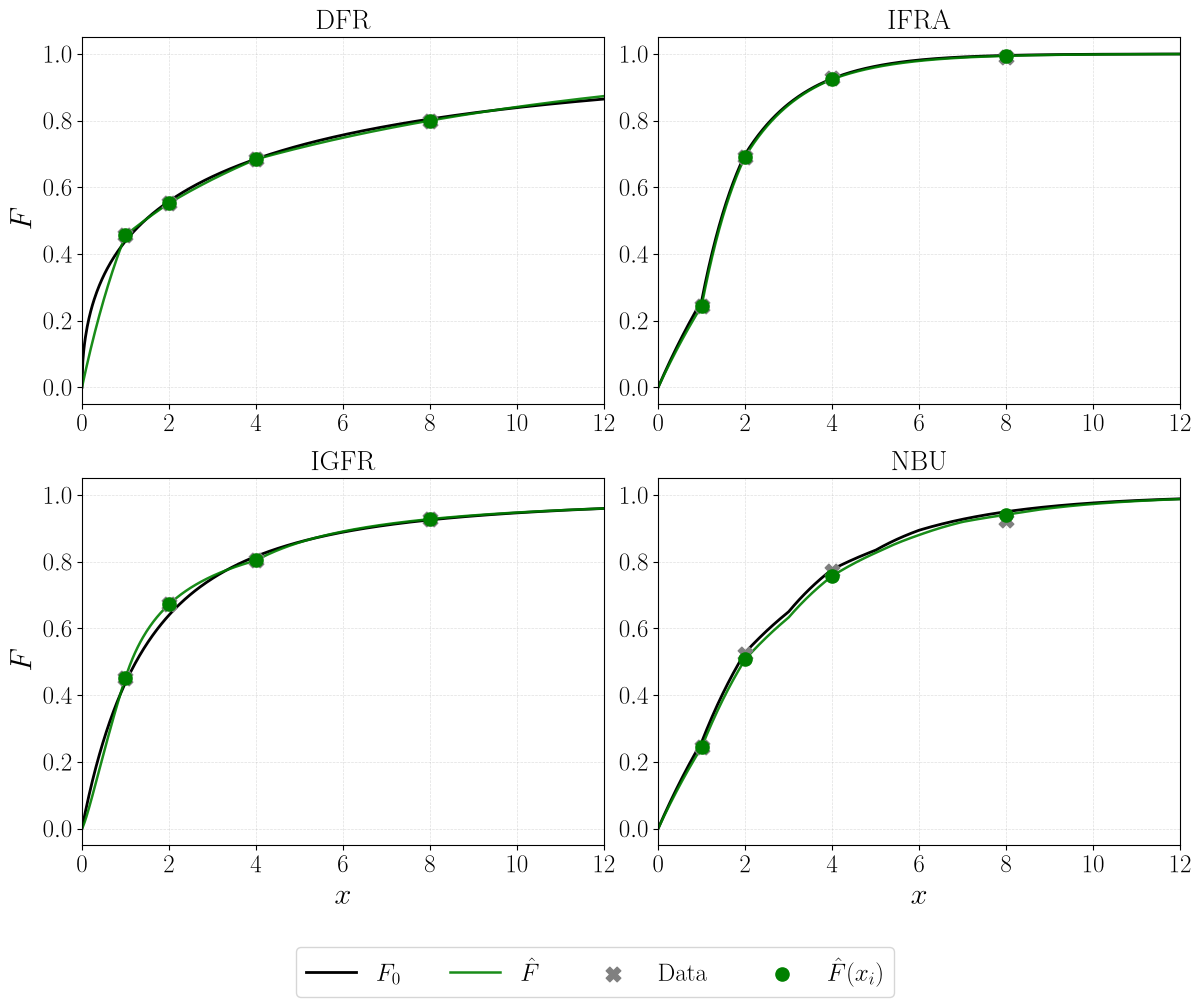

In [12]:
# ============================================================================
# Combined 2x2 figure (manuscript Appendix, "Visualization")
# ============================================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, p in zip(axes.ravel(), panels):
    ax.plot(p['x_grid'], p['y_true'], color='black', lw=2, label=r'$F_0$')
    ax.plot(p['x_grid'], p['y_fit'], color='green', lw=1.8, alpha=0.9, label=r'$\hat{F}$')
    ax.scatter(p['x_knots'], p['data'], color='grey', marker='X',
               s=110, zorder=5, label='Data')
    ax.scatter(p['x_knots'], p['fhat'], color='green', marker='o',
               s=90, zorder=6, label=r'$\hat{F}(x_i)$')
    ax.set_title(p['title'], fontsize=20)
    ax.set_xlim(*p['xlim'])
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.4)
for ax in axes[1, :]:
    ax.set_xlabel(r'$x$')
for ax in axes[:, 0]:
    ax.set_ylabel(r'$F$')

# Single shared legend below the four panels.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.06),
           ncol=4, fontsize=18, frameon=True)

plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig('results/plots/extension_examples_2x2.png', dpi=150, bbox_inches='tight')
plt.show()